In [1]:
import micropip
await micropip.install(['matplotlib', 'seaborn'])

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
orders_files = [
    "data/orders_2024_01.csv",
    "data/orders_2024_02.csv",
    "data/orders_2024_03.csv",
]
df_orders = pd.concat([pd.read_csv(f) for f in orders_files], ignore_index=True)
df_orders["order_datetime"] = pd.to_datetime(df_orders["order_datetime"])
df_orders["revenue"] = df_orders["price"] * df_orders["quantity"]
df_orders["order_date"] = df_orders["order_datetime"].dt.date
df_orders["order_hour"] = df_orders["order_datetime"].dt.hour
df_orders["weekday"] = df_orders["order_datetime"].dt.day_name()

print(df_orders.head())
print(df_orders.info())

   order_id  user_id      order_datetime  product_id     price  quantity  \
0         1     1044 2024-01-03 18:39:26          26  14038.15         1   
1         2     1079 2024-01-03 17:45:43          16   9172.60         1   
2         3     1041 2024-01-06 22:46:38          25   9035.26         2   
3         4     1083 2024-01-08 21:03:51           9  15234.33         3   
4         5     1068 2024-01-03 23:26:53          24   4134.38         2   

     status   revenue  order_date  order_hour    weekday  
0  refunded  14038.15  2024-01-03          18  Wednesday  
1      paid   9172.60  2024-01-03          17  Wednesday  
2      paid  18070.52  2024-01-06          22   Saturday  
3      paid  45702.99  2024-01-08          21     Monday  
4      paid   8268.76  2024-01-03          23  Wednesday  
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  --

In [5]:
orders_paid = df_orders[df_orders["status"] == "paid"].copy()
print(f"Всего заказов: {len(df_orders)} | paid: {len(orders_paid)} "
      f"({len(orders_paid)/len(df_orders):.1%})")

Всего заказов: 15000 | paid: 12032 (80.2%)


In [6]:
daily = (orders_paid.groupby("order_date")
         .agg(revenue=("revenue", "sum"),
              orders_count=("order_id", "count"),
              users_count=("user_id", "nunique"),
              avg_order_value=("revenue", "mean"))
         .reset_index())
daily["order_date"] = pd.to_datetime(daily["order_date"])

print("Таблица 1.")
print(daily.head(10).to_string(index=False))
print(f"\nВсего дней с продажами: {len(daily)}")

Таблица 1.
order_date    revenue  orders_count  users_count  avg_order_value
2024-01-01 3758095.21           135           69     27837.742296
2024-01-02 3405643.98           135           78     25226.992444
2024-01-03 3442816.40           136           81     25314.826471
2024-01-04 2961988.98           140           72     21157.064143
2024-01-05 3745680.93           144           78     26011.673125
2024-01-06 3526606.17           121           66     29145.505537
2024-01-07 2963003.35           125           75     23704.026800
2024-01-08 3091141.36           124           73     24928.559355
2024-01-09 3547841.02           144           84     24637.784861
2024-01-10 3194478.96           128           73     24956.866875

Всего дней с продажами: 91


In [7]:
weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

pivot_wh = (orders_paid.pivot_table(index="weekday",
                                    columns="order_hour",
                                    values="revenue",
                                    aggfunc="sum",
                                    fill_value=0)
            .reindex(weekday_order))

print("Таблица 2. Выручка по дням недели и часам:")
print(pivot_wh.round(0).to_string())

Таблица 2. Выручка по дням недели и часам:
order_hour         0          1          2          3          4          5          6          7          8          9          10         11         12         13         14         15         16         17         18         19         20         21         22         23
weekday                                                                                                                                                                                                                                                                           
Monday      1713642.0  1603284.0  1539845.0  1409014.0  1675459.0  1741129.0  2055423.0  1637427.0  1591154.0  2122773.0  2265361.0  1728054.0  2008346.0  1460705.0  1899283.0  1790560.0  2172595.0  1877665.0  1657546.0  1764253.0  1924405.0  1776677.0  1965753.0  1970372.0
Tuesday     1833258.0  1960237.0  1690558.0  2209379.0  1947574.0  1373895.0  1925821.0  1633136.0  1756752.0  1646294.0  1584625.0 

In [8]:
by_status = (df_orders.groupby("status")
             .agg(orders=("order_id", "count"),
                  revenue=("revenue", "sum"),
                  avg_qty=("quantity", "mean"))
             .reset_index())
by_status["share_orders"] = by_status["orders"] / by_status["orders"].sum()

print("Таблица 3. Сравнение по статусам")
print(by_status.round(3).to_string(index=False))

by_product = (orders_paid.groupby("product_id")
              .agg(orders=("order_id", "count"),
                   revenue=("revenue", "sum"),
                   avg_price=("price", "mean"))
              .reset_index()
              .sort_values("revenue", ascending=False))
by_product["revenue_share"] = by_product["revenue"] / by_product["revenue"].sum()

print("\nпо товарам:")
print(by_product.round(3).to_string(index=False))

Таблица 3. Сравнение по статусам
   status  orders      revenue  avg_qty  share_orders
cancelled    2212  56575865.30    2.459         0.147
     paid   12032 307828994.03    2.510         0.802
 refunded     756  20138792.46    2.552         0.050

по товарам:
 product_id  orders     revenue  avg_price  revenue_share
         13     449 11620213.78  10149.194          0.038
         20     438 11338577.93  10504.910          0.037
          1     414 11298261.74  10473.999          0.037
          4     425 10933634.15  10167.913          0.036
         22     435 10908053.91  10277.769          0.035
         14     405 10597959.01  10299.877          0.034
         26     407 10591631.16  10413.808          0.034
         17     425 10519375.03   9808.654          0.034
         10     408 10449183.67  10019.987          0.034
         30     399 10380137.43  10262.438          0.034
         11     377 10374598.21  10741.236          0.034
         25     418 10367294.41   9852.731

In [9]:
daily_full = (orders_paid.set_index("order_datetime")
              .resample("D")["revenue"].sum()
              .reset_index()
              .rename(columns={"order_datetime": "order_date"}))
daily_full["revenue"] = daily_full["revenue"].fillna(0)

daily_full["revenue_7d"] = (daily_full["revenue"]
                            .rolling(window=7, min_periods=1)
                            .mean())

print("7-дневное среднее:")
print(daily_full.head(10).round(0).to_string(index=False))

7-дневное среднее:


<ipython-input-9-cc3e9ff9e412>:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(daily_full.head(10).round(0).to_string(index=False))


order_date   revenue  revenue_7d
2024-01-01 3758095.0   3758095.0
2024-01-02 3405644.0   3581870.0
2024-01-03 3442816.0   3535519.0
2024-01-04 2961989.0   3392136.0
2024-01-05 3745681.0   3462845.0
2024-01-06 3526606.0   3473472.0
2024-01-07 2963003.0   3400548.0
2024-01-08 3091141.0   3305269.0
2024-01-09 3547841.0   3325583.0
2024-01-10 3194479.0   3290106.0


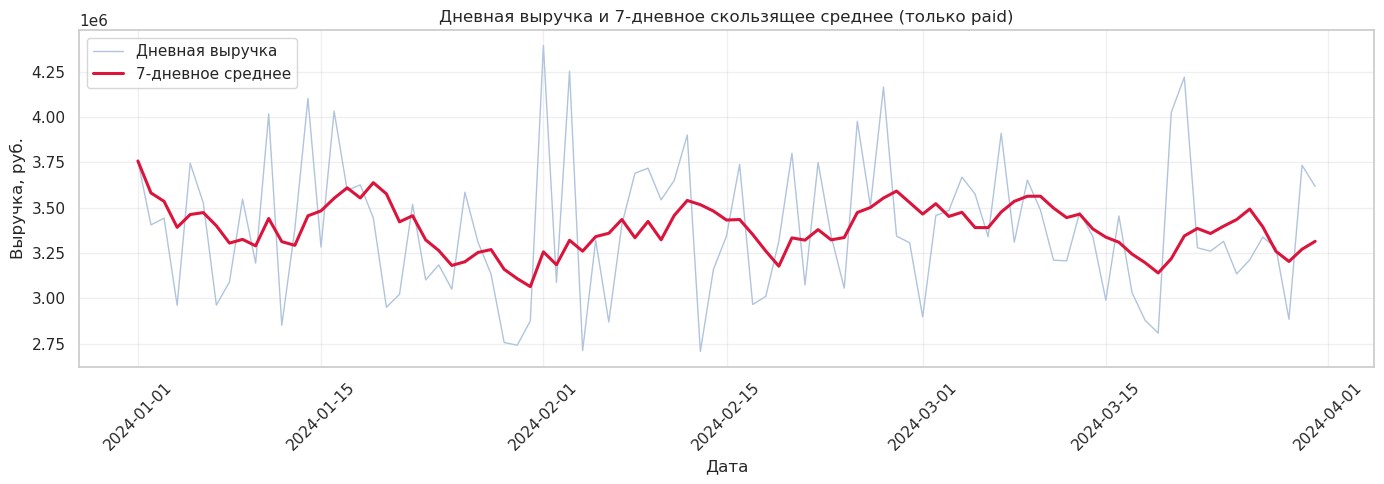

In [10]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_full["order_date"], daily_full["revenue"],
        label="Дневная выручка", color="lightsteelblue", linewidth=1)
ax.plot(daily_full["order_date"], daily_full["revenue_7d"],
        label="7-дневное среднее", color="crimson", linewidth=2.2)
ax.set_title("Дневная выручка и 7-дневное скользящее среднее (только paid)")
ax.set_xlabel("Дата"); ax.set_ylabel("Выручка, руб.")
ax.legend(); ax.grid(True, alpha=0.3)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

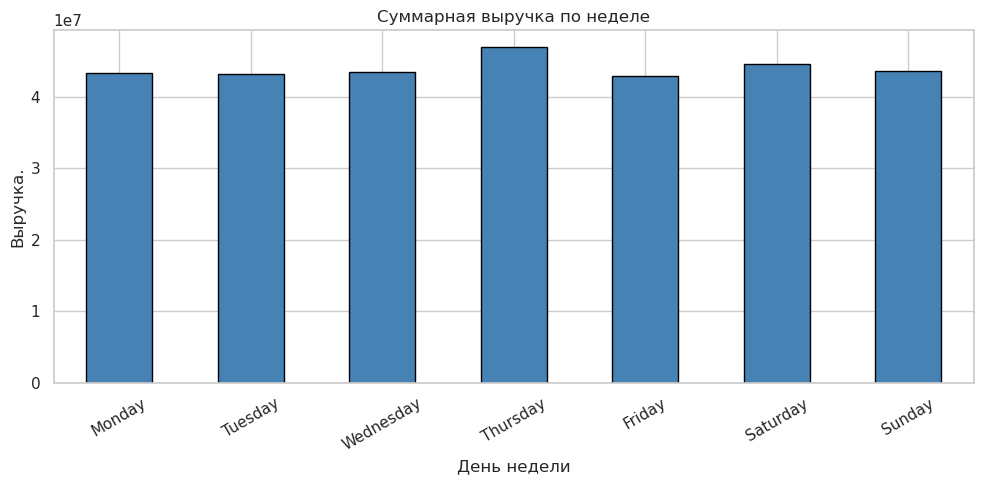

In [11]:
by_weekday = (daily_full.assign(weekday=daily_full["order_date"].dt.day_name())
              .groupby("weekday")["revenue"].sum()
              .reindex(weekday_order))

fig, ax = plt.subplots(figsize=(10, 5))
by_weekday.plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")
ax.set_title("Суммарная выручка по неделе")
ax.set_xlabel("День недели"); ax.set_ylabel("Выручка.")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

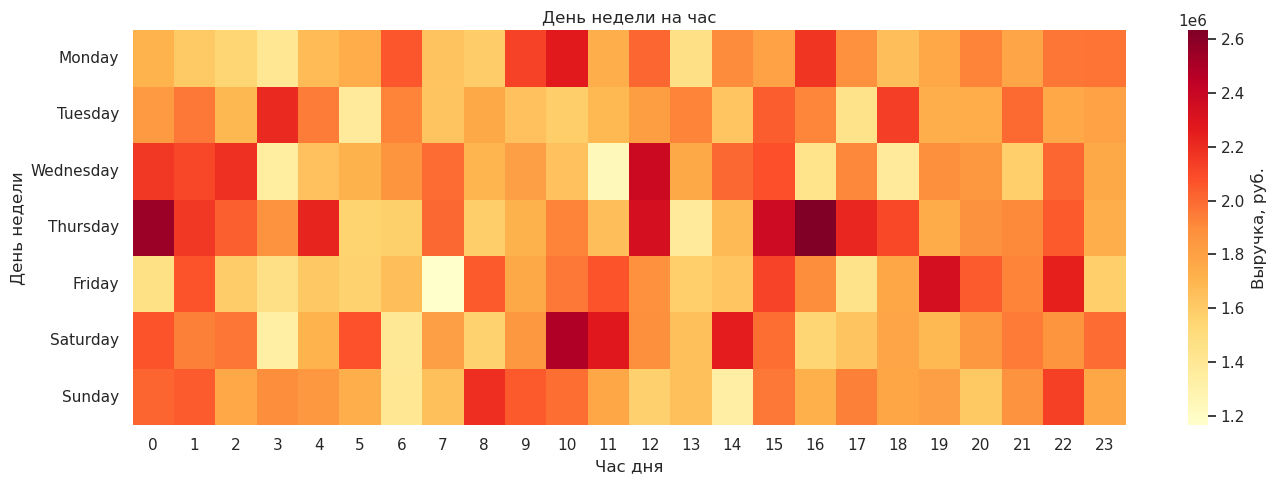

In [12]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot_wh, cmap="YlOrRd", annot=False, fmt=".0f",
            cbar_kws={"label": "Выручка, руб."}, ax=ax)
ax.set_title("День недели на час")
ax.set_xlabel("Час дня"); ax.set_ylabel("День недели")
plt.tight_layout(); plt.show()

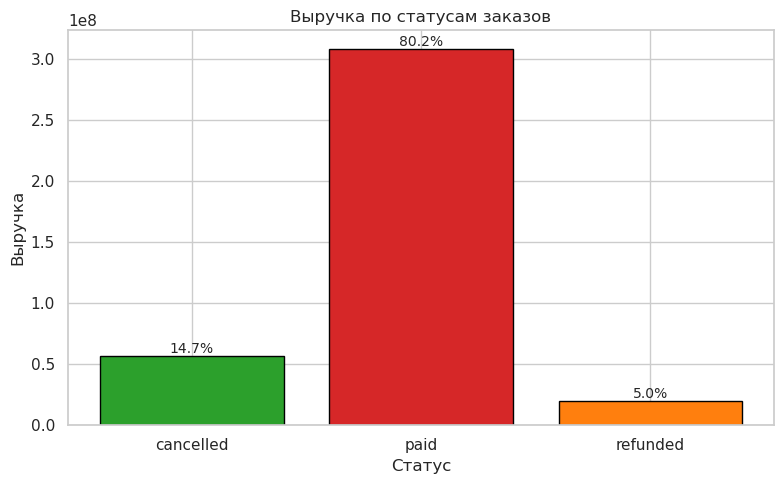

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(by_status["status"], by_status["revenue"],
              color=["#2ca02c", "#d62728", "#ff7f0e"], edgecolor="black")
ax.set_title("Выручка по статусам заказов")
ax.set_xlabel("Статус"); ax.set_ylabel("Выручка")
for b, s in zip(bars, by_status["share_orders"]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height(),
            f"{s:.1%}", ha="center", va="bottom", fontsize=10)
plt.tight_layout(); plt.show()

<ipython-input-14-a6840b7e82bd>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_orders, x="status", y="revenue",


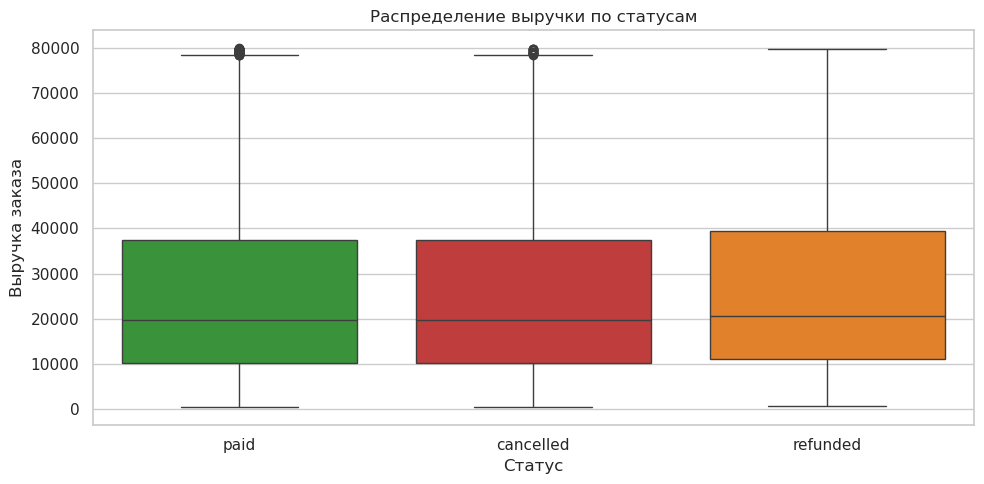

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df_orders, x="status", y="revenue",
            order=["paid", "cancelled", "refunded"], ax=ax,
            palette=["#2ca02c", "#d62728", "#ff7f0e"])
ax.set_title("Распределение выручки по статусам")
ax.set_xlabel("Статус"); ax.set_ylabel("Выручка заказа")
plt.tight_layout(); plt.show()

In [15]:
daily_full["growth_7d_abs"] = daily_full["revenue_7d"].diff(periods=7)
daily_full["growth_7d_pct"] = (daily_full["revenue_7d"]
                               .pct_change(periods=7) * 100)

idx_max_growth = daily_full["growth_7d_abs"].idxmax()
end_date = daily_full.loc[idx_max_growth, "order_date"]
start_date = end_date - pd.Timedelta(days=7)
max_growth = daily_full.loc[idx_max_growth, "growth_7d_abs"]
max_growth_pct = daily_full.loc[idx_max_growth, "growth_7d_pct"]

print(f"Период максимального роста")
print(f"  {start_date.date()} → {end_date.date()}")
print(f"  Прирост: +{max_growth:,.0f} руб. ({max_growth_pct:+.1f}%)")

print("\nТоп-3 периода роста:")
print(daily_full.nlargest(3, "growth_7d_abs")
      [["order_date", "revenue_7d", "growth_7d_abs", "growth_7d_pct"]]
      .round(1).to_string(index=False))

Период максимального роста
  2024-01-31 → 2024-02-07
  Прирост: +370,324 руб. (+12.1%)

Топ-3 периода роста:


<ipython-input-15-37bf0a8d8f45>:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(1).to_string(index=False))


order_date  revenue_7d  growth_7d_abs  growth_7d_pct
2024-02-07   3435379.3       370324.1           12.1
2024-03-26   3492865.9       352478.4           11.2
2024-01-19   3638503.1       325264.8            9.8


In [16]:
mask = (daily_full["order_date"] >= start_date) & (daily_full["order_date"] <= end_date)
print("Детализация периода роста:")
print(daily_full.loc[mask, ["order_date", "revenue", "revenue_7d"]]
      .round(0).to_string(index=False))

growth_orders = orders_paid[
    (orders_paid["order_datetime"] >= start_date) &
    (orders_paid["order_datetime"] <= end_date + pd.Timedelta(days=1))
]
print("\nТовары в период роста:")
print(growth_orders.groupby("product_id")
      .agg(orders=("order_id", "count"), revenue=("revenue", "sum"))
      .sort_values("revenue", ascending=False).to_string())

Детализация периода роста:


<ipython-input-16-574cb1d2c365>:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(0).to_string(index=False))


order_date   revenue  revenue_7d
2024-01-31 2875789.0   3065055.0
2024-02-01 4394521.0   3256980.0
2024-02-02 3088038.0   3185903.0
2024-02-03 4253986.0   3320698.0
2024-02-04 2712264.0   3260494.0
2024-02-05 3321058.0   3341076.0
2024-02-06 2870137.0   3359399.0
2024-02-07 3407650.0   3435379.0

Товары в период роста:
            orders     revenue
product_id                    
26              40  1318694.90
8               46  1231248.40
18              45  1166669.08
9               36  1136164.04
20              37  1058698.59
30              40  1052995.57
3               41  1049817.45
21              38  1014038.35
24              48  1007055.35
25              37   988403.70
12              39   955814.90
17              43   934101.47
7               37   915727.25
22              34   858267.38
11              33   856626.38
13              28   838139.98
16              33   830160.38
14              35   822497.94
23              33   809996.29
28              38   801685.